# Khám phá dữ liệu UIT-VSFC

Notebook đọc các CSV đã chuẩn bị trong `data/processed/` và đối chiếu chúng với `manifest.json`. Các bảng bên dưới tóm tắt phân bố nhãn, độ dài văn bản và câu trùng trong ba split chính thức.

In [1]:
from hashlib import sha256
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from sentiment.data.loaders import TextExample
from sentiment.data.split import validate_splits

repo_root = Path.cwd()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent

data_dir = repo_root / "data" / "processed"
figures_dir = repo_root / "reports" / "figures"
splits = ("train", "dev", "test")
labels = {0: "Tiêu cực", 1: "Trung tính", 2: "Tích cực"}
columns = ["id", "split", "text_raw", "text", "label_id"]
dtypes = {"id": str, "split": str, "text_raw": str, "text": str, "label_id": "int64"}

required_files = [data_dir / "manifest.json", *(data_dir / f"{split}.csv" for split in splits)]
missing = [str(path) for path in required_files if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Chạy scripts/prepare_data.py trước khi mở EDA. Thiếu " + ", ".join(missing)
    )

with (data_dir / "manifest.json").open(encoding="utf-8") as handle:
    manifest = json.load(handle)

frames = {}
checks = []
for split in splits:
    csv_path = data_dir / f"{split}.csv"
    split_manifest = manifest["splits"][split]
    expected_file = split_manifest["processed_file"]
    checksum = sha256(csv_path.read_bytes()).hexdigest()
    if csv_path.name != expected_file["path"] or checksum != expected_file["sha256"]:
        raise ValueError(f"Tệp {csv_path.name} không khớp tên hoặc SHA-256 trong manifest.")

    frame = pd.read_csv(csv_path, dtype=dtypes, keep_default_na=False, encoding="utf-8")
    if frame.columns.tolist() != columns:
        raise ValueError(f"Sai schema trong {csv_path.name}.")
    if frame.empty or len(frame) != split_manifest["num_samples"] or not frame["split"].eq(split).all():
        raise ValueError(f"Sai số mẫu hoặc tên split trong {csv_path.name}.")
    if not frame["label_id"].isin(labels).all():
        raise ValueError(f"Có nhãn ngoài 0, 1, 2 trong {csv_path.name}.")

    frames[split] = frame
    checks.append({"split": split, "số mẫu": len(frame), "SHA-256 khớp": True})

data = pd.concat(frames.values(), ignore_index=True)
if data["id"].eq("").any() or not data["id"].is_unique:
    raise ValueError("Dữ liệu chứa ID trống hoặc bị trùng.")

figures_dir.mkdir(parents=True, exist_ok=True)
pd.DataFrame(checks).set_index("split")

,số mẫu,SHA-256 khớp
split,,
train,11426,True
dev,1583,True
test,3166,True


## Phân bố nhãn theo split

Đối chiếu số mẫu từng nhãn với manifest. Biểu đồ cho thấy tỷ lệ lớp trong từng tập.

label_id,Tiêu cực,Trung tính,Tích cực,Tổng
split,,,,
train,5325,458,5643,11426
dev,705,73,805,1583
test,1409,167,1590,3166


label_id,Tiêu cực,Trung tính,Tích cực
split,,,
train,46.60,4.01,49.39
dev,44.54,4.61,50.85
test,44.50,5.27,50.22


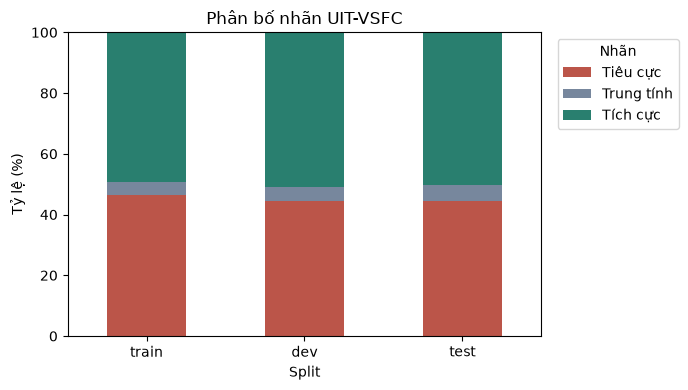

In [2]:
label_counts = pd.crosstab(data["split"], data["label_id"]).reindex(
    index=splits, columns=list(labels), fill_value=0
)
for split in splits:
    counts = {str(label_id): int(label_counts.loc[split, label_id]) for label_id in labels}
    if counts != manifest["splits"][split]["label_counts"]:
        raise ValueError(f"Phân bố nhãn của {split} không khớp manifest.")

display(label_counts.rename(columns=labels).assign(Tổng=label_counts.sum(axis=1)))

label_shares = label_counts.div(label_counts.sum(axis=1), axis=0).mul(100).rename(columns=labels)
display(label_shares.round(2))

ax = label_shares.plot.bar(
    stacked=True, color=["#BB5549", "#77879D", "#297F6F"], rot=0, figsize=(7, 4)
)
ax.set(xlabel="Split", ylabel="Tỷ lệ (%)", title="Phân bố nhãn UIT-VSFC", ylim=(0, 100))
ax.legend(title="Nhãn", loc="upper left", bbox_to_anchor=(1.02, 1))
ax.figure.tight_layout()
ax.figure.savefig(figures_dir / "eda_label_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## Độ dài văn bản

Đo trên cột `text` đã làm sạch và chưa tách từ. Số đơn vị theo khoảng trắng mô tả độ dài đầu vào trước bước tách từ.

,median_chars,p95_chars,max_chars,median_units,p95_units,max_units
split,,,,,,
train,47.0,141.0,660,11.0,33.0,159
dev,45.0,132.0,718,11.0,31.0,161
test,46.0,147.0,411,11.0,34.0,98


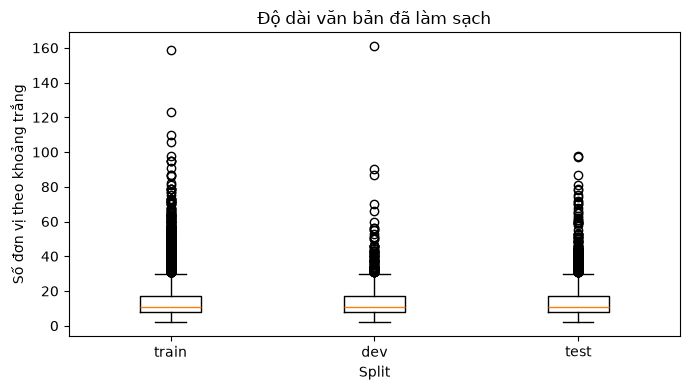

In [3]:
lengths = data.assign(
    characters=data["text"].str.len(),
    whitespace_units=data["text"].str.split().str.len(),
)
length_stats = lengths.groupby("split").agg(
    median_chars=("characters", "median"),
    p95_chars=("characters", lambda values: values.quantile(0.95)),
    max_chars=("characters", "max"),
    median_units=("whitespace_units", "median"),
    p95_units=("whitespace_units", lambda values: values.quantile(0.95)),
    max_units=("whitespace_units", "max"),
).reindex(splits)
display(length_stats.round(1))

fig, ax = plt.subplots(figsize=(7, 4))
groups = [lengths.loc[lengths["split"].eq(split), "whitespace_units"] for split in splits]
ax.boxplot(groups)
ax.set_xticks([1, 2, 3], labels=splits)
ax.set(xlabel="Split", ylabel="Số đơn vị theo khoảng trắng", title="Độ dài văn bản đã làm sạch")
fig.tight_layout()
fig.savefig(figures_dir / "eda_text_length.png", dpi=150, bbox_inches="tight")
plt.show()

## Câu trùng trong và giữa các split

`validate_splits()` tạo khóa đối chiếu từ `text_raw` bằng Unicode NFC, chuẩn hóa khoảng trắng và `casefold()`. Bảng trong mỗi split đếm số dòng lặp ngoài lần xuất hiện đầu tiên. Bảng giữa các split đếm số khóa chung của từng cặp.

In [4]:
examples_by_split = {
    split: [
        TextExample(sample_id, text_raw, int(label_id))
        for sample_id, text_raw, label_id in frame[["id", "text_raw", "label_id"]].itertuples(
            index=False, name=None
        )
    ]
    for split, frame in frames.items()
}
validation = validate_splits(examples_by_split)
duplicate_rows = {split: stats["duplicate_rows"] for split, stats in validation["splits"].items()}
overlaps = validation["cross_split_overlaps"]

for split, count in duplicate_rows.items():
    if count != manifest["splits"][split]["duplicate_rows"]:
        raise ValueError(f"Số dòng lặp của {split} không khớp manifest.")
if overlaps != manifest["cross_split_overlaps"]:
    raise ValueError("Số câu trùng giữa các split không khớp manifest.")

display(pd.Series(duplicate_rows, name="Số dòng lặp").rename_axis("split").to_frame())
display(pd.Series(overlaps, name="Số khóa chung").rename_axis("Cặp split").to_frame())

,Số dòng lặp
split,
train,1
dev,0
test,0


,Số khóa chung
Cặp split,
train/dev,0
train/test,0
dev/test,0
